In [1]:
import gpxpy
import gpxpy.gpx

# Parsing an existing file:
# -------------------------

with open('/home/daniel/Downloads/glas-maol.gpx', 'r') as gpx_file:

    gpx = gpxpy.parse(gpx_file)

In [2]:
import matplotlib.pyplot as plt

In [3]:
from cycler import cycler

style = {
    "xtick.labelsize":10,
    "xtick.major.size": 5,
    "xtick.minor.visible": True,
    "xtick.color": "k",
    "ytick.labelsize":10,
    "ytick.major.size": 5,
    "ytick.minor.visible": True,
    # Lines
    "lines.linewidth": 2,
    "axes.prop_cycle": cycler("color", ['#8dd3c7', '#ffffb3', '#bebada',
                                        '#fb8072', '#80b1d3', '#fdb462',
                                        '#b3de69', '#fccde5', '#d9d9d9',
                                        '#bc80bd', '#ccebc5', '#ffed6f']),
    # Fonts
    "font.monospace": ["Source Code Pro"],
    "font.sans-serif": ["Source Sans Pro"],
    "font.family": "monospace",
    # Grid
    "grid.color": "#4298bd",
    "grid.alpha": 0.5,
    # Display
    "figure.dpi": 300,
    # Face colors
    "axes.facecolor": "#ecf5f8",
    "figure.facecolor": "#FFFFFFFF"
}

In [4]:
plt.style.use(style)

In [5]:
import numpy as np

In [6]:
distances = []
true_distances = [] 
elevations = []
lats, lons = [], []
for i in range(len(gpx.routes[0].points)-1):
    distances.append(gpx.routes[0].points[i].distance_2d(gpx.routes[0].points[i+1]))
    true_distances.append(gpx.routes[0].points[i].distance_3d(gpx.routes[0].points[i+1]))
    elevations.append(gpx.routes[0].points[i].elevation)
    lats.append(gpx.routes[0].points[i].latitude)
    lons.append(gpx.routes[0].points[i].longitude)
elevations = np.array(elevations)
lats = np.array(lats)
lons = np.array(lons)

In [7]:
def condition_runs(condition):
    # Create an array that is 1 where a is 0, and pad each end with an extra 0.
    changes = np.concatenate([[condition[0]], np.diff(condition)])
    
    ranges = np.where(changes==True)[0]
    if len(ranges)%2!=0:
        ranges = np.concatenate([ranges, [len(ranges)]])
    ranges = ranges.reshape(-1,2)
    
    return ranges

In [8]:
gradients = np.rad2deg(np.sin(np.diff(elevations)/distances[1:]/0.90))

In [9]:
import matplotlib.cm as cm
cmap = cm.get_cmap("RdBu", 10)

In [10]:
import matplotlib.ticker as ticker

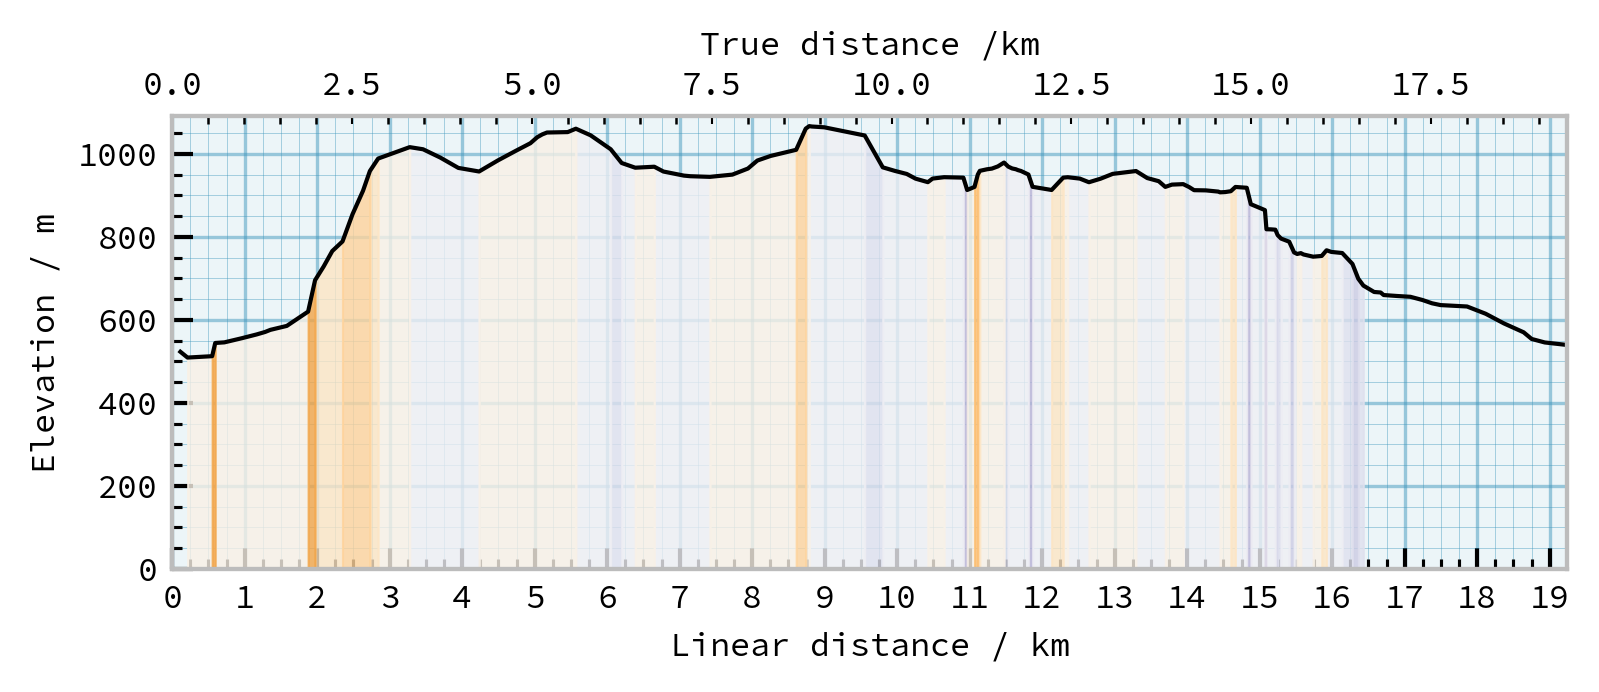

In [11]:
f, ax = plt.subplots(1,1, dpi=300, figsize=(6, 2))
gradients =  np.rad2deg(np.arctan(np.concatenate([[0], np.diff(elevations)])/distances))/0.9

#np.rad2deg(np.tan(np.concatenate([[0], np.diff(elevations)])/distances/0.90))
#ax.plot(np.cumsum(distances)[1:], gradients)

conditions = np.vstack([
    np.concatenate([np.arange(-100,0,10), np.arange(0,100,10)]),
    np.concatenate([np.arange(-90,0,10), np.arange(0,110,10)],),
]).T
cmap = cm.get_cmap("PuOr_r", len(conditions))
for color, condition in enumerate(conditions):
    for block in condition_runs((gradients>=condition[0]) & (gradients<=condition[1])):
        profile = ax.fill_between(np.cumsum(distances)[block[0]-1:block[1]]/1000, 
                        elevations[block[0]-1:block[1]], color=cmap(color), alpha=0.8)
ax.set_xlim(0, np.cumsum(distances).max()/1000)
ax.set_ylim(0, elevations.max()+25)

ax.plot(np.cumsum(distances)/1000, elevations, lw=1, color='k')
#ax.axhline([915], lw=0.5, color='#333333')

ax2=ax.twiny()
ax2.grid(False)
ax2.plot(np.cumsum(true_distances)/1000, elevations, alpha=0)
ax2.set_xlim(0, np.cumsum(true_distances).max()/1000)
ax2.set_xlabel("True distance /km")
ax2.tick_params(which='major', width=0.5, length=2, labelsize=8)

ax.set_ylabel("Elevation / m")
ax.set_xlabel("Linear distance / km")
ax.xaxis.set_major_locator(ticker.MultipleLocator(1.00))
ax.xaxis.set_minor_locator(ticker.MultipleLocator(0.25))
ax.yaxis.set_minor_locator(ticker.MultipleLocator(50))
ax.grid("both")
ax.tick_params(which='major', width=1.00, length=5, labelsize=8)
ax.tick_params(which='minor', width=0.75, length=2.5, labelsize=10)
ax.grid(b=True, which='minor', linestyle='-', lw=0.2)
#f.colorbar(cm.ScalarMappable(cmap=cmap), ax=ax)

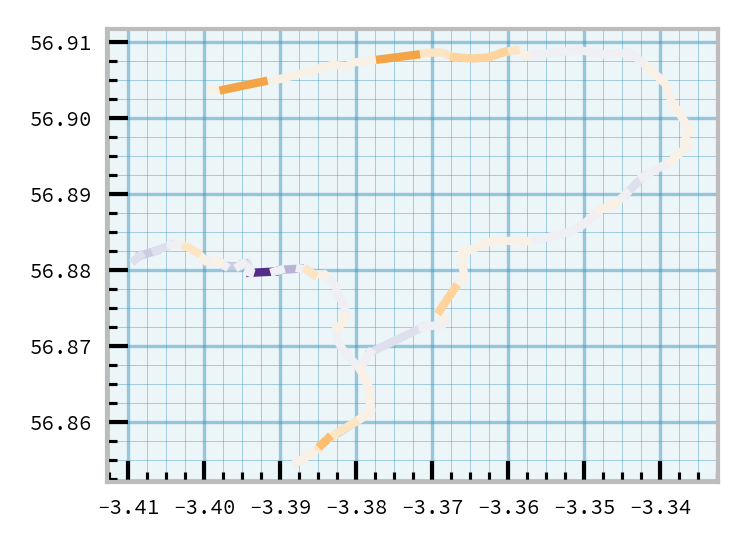

In [12]:
f, ax = plt.subplots(1,1, dpi=300, figsize=(6, 2))
gradients =  np.rad2deg(np.arctan(np.concatenate([[0], np.diff(elevations)])/distances))/0.9

#np.rad2deg(np.tan(np.concatenate([[0], np.diff(elevations)])/distances/0.90))
#ax.plot(np.cumsum(distances)[1:], gradients)

conditions = np.vstack([
    np.concatenate([np.arange(-100,0,10), np.arange(0,100,10)]),
    np.concatenate([np.arange(-90,0,10), np.arange(0,110,10)],),
]).T
cmap = cm.get_cmap("PuOr_r", len(conditions))
for color, condition in enumerate(conditions):
    for block in condition_runs((gradients>=condition[0]) & (gradients<=condition[1])):
        profile = ax.plot(lons[block[0]-1:block[1]], 
                          lats[block[0]-1:block[1]],
                          lw=2,
                          color=cmap(color), alpha=1.0)

#ax.set_ylabel("Elevation / m")
#ax.set_xlabel("Linear distance / km")
ax.set_aspect("equal")
ax.xaxis.set_major_locator(ticker.MultipleLocator(0.01))
ax.xaxis.set_minor_locator(ticker.MultipleLocator(0.0025))
ax.yaxis.set_major_locator(ticker.MultipleLocator(0.01))
ax.yaxis.set_minor_locator(ticker.MultipleLocator(0.0025))
ax.grid("both")
ax.tick_params(which='major', width=1.00, length=5, labelsize=5)
ax.tick_params(which='minor', width=0.75, length=2.5, labelsize=10)
ax.grid(b=True, which='minor', linestyle='-', lw=0.2)
#f.colorbar(cm.ScalarMappable(cmap=cmap), ax=ax)

In [ ]:
gpx.routes[0].points[0].extensions